In [ ]:
"""
TranSenseFuser XAI Attribution Computation and Storage
Computes SHAP, LIME, and IG attributions for TranSenseFuser model
and saves per-sample raw data for downstream metric evaluation

Key Differences from CNN-LSTM version:
1. Window size: 21000 → 7000 samples (30s → 10s)
2. Model: StressCNNLSTM → TranSenseFuser (CNN + Multi-Head Attention)
3. Adjusted LIME downsampling: 30 → 10 (for 7000 samples)

Output: .npy file containing attribution matrices for all samples
Shape: (n_samples, n_methods, n_channels, n_timesteps)
"""

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm import tqdm
import os
import warnings
warnings.filterwarnings('ignore')

# ===============================================================
# CONFIGURATION
# ===============================================================

class Config:
    # Paths
    DATA_PATH = '/content/drive/MyDrive/WESAD/'
    MODEL_PATH = '/content/drive/MyDrive/WESAD/TranSenseFusers All Models And XAIs/models_transensefusers_10s/best_transensefuser_10s.pth'
    XAI_DATA_PATH = '/content/drive/MyDrive/WESAD/TranSenseFusers All Models And XAIs/xai_transensefusers_10s/xai_S3_transensefusers_10s.npy'
    OUTPUT_DIR = '/content/drive/MyDrive/WESAD/TranSenseFusers All Models And XAIs/xai_transensefusers_10s'

    # Model parameters - TranSenseFuser
    NUM_CHANNELS = 14
    NUM_CLASSES = 2
    WINDOW_SIZE = 7000  # 10s at 700Hz

    # TranSenseFusers architecture
    NUM_HEADS = 8
    ATTENTION_DIM = 64
    CONV_DROPOUT = 0.1
    FC_DROPOUT = 0.5
    ATTENTION_DROPOUT = 0.0

    # Channel names
    CHANNEL_NAMES = [
        'Chest_ACC_x', 'Chest_ACC_y', 'Chest_ACC_z',
        'ECG', 'EMG', 'Chest_EDA', 'Chest_Temp', 'Resp',
        'Wrist_ACC_x', 'Wrist_ACC_y', 'Wrist_ACC_z',
        'BVP', 'Wrist_EDA', 'Wrist_Temp'
    ]

    # Attribution parameters
    N_SAMPLES = 100  # Number of samples to compute attributions for
    IG_STEPS = 50    # Integration steps for IG
    LIME_DOWNSAMPLE = 10  # Downsample factor for LIME (7000 -> 700)
    LIME_NUM_SAMPLES = 500  # LIME perturbation samples

    # Device
    DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

config = Config()
os.makedirs(config.OUTPUT_DIR, exist_ok=True)

print("="*70)
print("TRANSENSEFUSER XAI ATTRIBUTION COMPUTATION & STORAGE")
print("="*70)
print(f"Device: {config.DEVICE}")
print(f"Model: TranSenseFuser (CNN + {config.NUM_HEADS}-head Attention)")
print(f"Channels: {config.NUM_CHANNELS}")
print(f"Window size: {config.WINDOW_SIZE} (10s)")
print(f"Samples to process: {config.N_SAMPLES}")

# ===============================================================
# MODEL DEFINITION - TranSenseFuser
# ===============================================================

class MultiHeadCrossAttention(nn.Module):
    """Multi-Head Cross-Attention module"""
    def __init__(self, num_heads, d_model, dropout=0.0):
        super().__init__()
        assert d_model % num_heads == 0

        self.num_heads = num_heads
        self.d_model = d_model
        self.d_k = d_model // num_heads

        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)

        self.dropout = nn.Dropout(dropout)
        self.scale = np.sqrt(self.d_k)

    def forward(self, query, key, value):
        batch_size = query.size(0)

        Q = self.W_q(query).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)
        K = self.W_k(key).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)
        V = self.W_v(value).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)

        scores = torch.matmul(Q, K.transpose(-2, -1)) / self.scale
        attention_weights = F.softmax(scores, dim=-1)
        attention_weights = self.dropout(attention_weights)

        context = torch.matmul(attention_weights, V)
        context = context.transpose(1, 2).contiguous().view(batch_size, -1, self.d_model)
        output = self.W_o(context)

        return output, attention_weights


class TranSenseFuser(nn.Module):
    """TranSenseFusers: Temporal CNN + Multi-Head Cross-Attention"""
    def __init__(self, num_channels=14, num_classes=2, num_heads=8, attention_dim=64,
                 conv_dropout=0.1, fc_dropout=0.5, attention_dropout=0.0):
        super().__init__()

        self.num_channels = num_channels
        self.num_classes = num_classes

        # Temporal CNN
        self.conv1 = nn.Conv1d(num_channels, 32, kernel_size=9, padding=4)
        self.bn1 = nn.BatchNorm1d(32)
        self.pool1 = nn.MaxPool1d(2)
        self.drop1 = nn.Dropout(conv_dropout)

        self.conv2 = nn.Conv1d(32, 48, kernel_size=9, padding=4)
        self.bn2 = nn.BatchNorm1d(48)
        self.pool2 = nn.MaxPool1d(2)
        self.drop2 = nn.Dropout(conv_dropout)

        self.conv3 = nn.Conv1d(48, 64, kernel_size=9, padding=4)
        self.bn3 = nn.BatchNorm1d(64)
        self.pool3 = nn.MaxPool1d(2)
        self.drop3 = nn.Dropout(conv_dropout)

        # Attention
        self.feature_to_attention = nn.Linear(64, attention_dim)
        self.mhca = MultiHeadCrossAttention(num_heads, attention_dim, attention_dropout)
        self.layer_norm = nn.LayerNorm(attention_dim)

        # Classification (7000/2/2/2 = 875)
        self.fc1 = nn.Linear(attention_dim * 875, 32)
        self.bn4 = nn.BatchNorm1d(32)
        self.drop4 = nn.Dropout(fc_dropout)
        self.fc2 = nn.Linear(32, num_classes)

    def forward(self, x, return_attention=False):
        # CNN blocks
        x = self.drop1(self.pool1(F.relu(self.bn1(self.conv1(x)))))
        x = self.drop2(self.pool2(F.relu(self.bn2(self.conv2(x)))))
        x = self.drop3(self.pool3(F.relu(self.bn3(self.conv3(x)))))

        # Attention
        x = x.transpose(1, 2)
        x = self.feature_to_attention(x)

        mid_point = x.size(2) // 2
        query = torch.cat([x[:, :, :mid_point], x[:, :, :mid_point]], dim=2)
        key_value = torch.cat([x[:, :, mid_point:], x[:, :, mid_point:]], dim=2)

        attention_output, attention_weights = self.mhca(query, key_value, key_value)
        attention_output = self.layer_norm(attention_output)

        # Classification
        x_flat = attention_output.flatten(1)
        x_flat = self.drop4(F.relu(self.bn4(self.fc1(x_flat))))
        logits = self.fc2(x_flat)

        if return_attention:
            return logits, attention_weights
        return logits

# ===============================================================
# LOAD MODEL AND DATA
# ===============================================================

def load_model_and_data(config):
    print("\n📂 Loading TranSenseFuser model and data...")

    model = TranSenseFuser(
        num_channels=config.NUM_CHANNELS,
        num_classes=config.NUM_CLASSES,
        num_heads=config.NUM_HEADS,
        attention_dim=config.ATTENTION_DIM,
        conv_dropout=config.CONV_DROPOUT,
        fc_dropout=config.FC_DROPOUT,
        attention_dropout=config.ATTENTION_DROPOUT
    ).to(config.DEVICE)

    checkpoint = torch.load(config.MODEL_PATH, map_location=config.DEVICE)
    model.load_state_dict(checkpoint['model_state_dict'])
    model.eval()
    print(f"   ✓ TranSenseFuser loaded (Val F1: {checkpoint['val_f1']:.4f})")

    xai_data = np.load(config.XAI_DATA_PATH, allow_pickle=True).item()
    X_test = xai_data['X_test']
    y_test = np.array(xai_data['y_test'])
    predictions = np.array(xai_data['predictions'])

    print(f"   ✓ Data loaded: {X_test.shape}")
    print(f"   ✓ Accuracy: {np.mean(predictions == y_test)*100:.2f}%")

    return model, X_test, y_test, predictions

# ===============================================================
# SHAP ATTRIBUTION (Gradient-based)
# ===============================================================

def compute_shap_attributions(model, X_samples, config):
    """
    Compute SHAP-like attributions using gradient × input
    ADAPTED for TranSenseFuser (has Attention, BatchNorm, LayerNorm)
    Returns: (n_samples, n_channels, n_timesteps)
    """
    print("\n🔍 Computing SHAP attributions for TranSenseFuser...")

    # Set model for gradient computation
    model.train()
    for module in model.modules():
        if isinstance(module, nn.BatchNorm1d):
            module.eval()  # Keep BatchNorm in eval mode
        if isinstance(module, nn.Dropout):
            module.p = 0.0  # Disable dropout
        if isinstance(module, nn.LayerNorm):
            module.eval()  # Keep LayerNorm in eval mode

    shap_attributions = []

    for i in tqdm(range(len(X_samples)), desc="SHAP"):
        x = torch.FloatTensor(X_samples[i:i+1]).to(config.DEVICE)
        x.requires_grad = True

        # Forward pass (no need for attention maps)
        output = model(x, return_attention=False)
        stress_score = output[0, 1]

        # Backward pass
        model.zero_grad()
        stress_score.backward()

        # Compute attribution (gradient × input)
        attribution = (x.grad * x).detach().cpu().numpy()[0]
        shap_attributions.append(attribution)

    model.eval()

    shap_attributions = np.array(shap_attributions)
    print(f"   ✓ SHAP shape: {shap_attributions.shape}")

    return shap_attributions

# ===============================================================
# LIME ATTRIBUTION
# ===============================================================

def compute_lime_attributions(model, X_samples, config):
    """
    Compute LIME attributions with downsampling and upsampling
    ADAPTED for TranSenseFuser (10s windows, downsample factor = 10)
    Returns: (n_samples, n_channels, n_timesteps)
    """
    print("\n🔍 Computing LIME attributions for TranSenseFuser...")

    from lime import lime_tabular

    # Downsample
    X_downsampled = X_samples[:, :, ::config.LIME_DOWNSAMPLE]
    print(f"   Downsampled: {X_samples.shape} -> {X_downsampled.shape}")

    X_flat = X_downsampled.reshape(X_downsampled.shape[0], -1)
    downsampled_timesteps = X_downsampled.shape[2]

    def predict_fn(X):
        X_reshaped = X.reshape(X.shape[0], config.NUM_CHANNELS, -1)
        X_upsampled = np.zeros((X.shape[0], config.NUM_CHANNELS, config.WINDOW_SIZE))

        for i in range(X.shape[0]):
            for ch in range(config.NUM_CHANNELS):
                X_upsampled[i, ch] = np.interp(
                    np.linspace(0, X_reshaped.shape[2]-1, config.WINDOW_SIZE),
                    np.arange(X_reshaped.shape[2]),
                    X_reshaped[i, ch]
                )

        X_tensor = torch.FloatTensor(X_upsampled).to(config.DEVICE)
        model.eval()
        with torch.no_grad():
            outputs = model(X_tensor, return_attention=False)
            probs = F.softmax(outputs, dim=1)
        return probs.cpu().numpy()

    explainer = lime_tabular.LimeTabularExplainer(
        X_flat,
        mode='classification',
        feature_names=None,
        class_names=['Non-Stress', 'Stress'],
        discretize_continuous=False
    )

    lime_attributions_downsampled = np.zeros((len(X_samples), config.NUM_CHANNELS, downsampled_timesteps))

    for idx in tqdm(range(len(X_samples)), desc="LIME"):
        explanation = explainer.explain_instance(
            X_flat[idx],
            predict_fn,
            num_features=50,
            num_samples=config.LIME_NUM_SAMPLES,
            labels=(1,)
        )

        feature_weights = explanation.as_list()

        for feature_str, weight in feature_weights:
            try:
                feature_idx = int(feature_str.split('<=')[0].split('>')[0].strip())
                channel_idx = feature_idx // downsampled_timesteps
                time_idx = feature_idx % downsampled_timesteps

                if channel_idx < config.NUM_CHANNELS and time_idx < downsampled_timesteps:
                    lime_attributions_downsampled[idx, channel_idx, time_idx] = weight
            except:
                continue

    # Upsample back to original resolution
    print(f"   Upsampling LIME attributions to {config.WINDOW_SIZE} timesteps...")
    lime_attributions = np.zeros((len(X_samples), config.NUM_CHANNELS, config.WINDOW_SIZE))

    for i in range(len(X_samples)):
        for ch in range(config.NUM_CHANNELS):
            lime_attributions[i, ch] = np.interp(
                np.linspace(0, downsampled_timesteps-1, config.WINDOW_SIZE),
                np.arange(downsampled_timesteps),
                lime_attributions_downsampled[i, ch]
            )

    print(f"   ✓ LIME shape: {lime_attributions.shape}")

    return lime_attributions

# ===============================================================
# INTEGRATED GRADIENTS
# ===============================================================

def integrated_gradients(model, X, steps=50):
    """
    Compute Integrated Gradients for TranSenseFuser
    ADAPTED: No LSTM, has Attention mechanism
    """
    baseline = torch.zeros_like(X)
    accumulated_gradients = torch.zeros_like(X)

    alphas = torch.linspace(0, 1, steps)

    for alpha in alphas:
        interpolated = baseline + alpha * (X - baseline)
        interpolated.requires_grad_(True)

        # Forward pass (no attention maps needed)
        output = model(interpolated, return_attention=False)
        target_class = output[:, 1]

        model.zero_grad()
        target_class.sum().backward()

        accumulated_gradients += interpolated.grad.detach()

        interpolated.grad = None
        del interpolated, output, target_class
        torch.cuda.empty_cache()

    avg_gradients = accumulated_gradients / steps
    ig = (X - baseline) * avg_gradients

    return ig

def compute_ig_attributions(model, X_samples, config):
    """
    Compute Integrated Gradients attributions for TranSenseFuser
    Returns: (n_samples, n_channels, n_timesteps)
    """
    print("\n🔍 Computing Integrated Gradients attributions for TranSenseFuser...")

    # Set model for gradient computation
    model.train()
    for module in model.modules():
        if isinstance(module, nn.BatchNorm1d):
            module.eval()
        if isinstance(module, nn.Dropout):
            module.p = 0.0
        if isinstance(module, nn.LayerNorm):
            module.eval()

    ig_attributions = []

    for i in tqdm(range(len(X_samples)), desc="IG"):
        x = torch.FloatTensor(X_samples[i:i+1]).to(config.DEVICE)

        with torch.enable_grad():
            ig = integrated_gradients(model, x, steps=config.IG_STEPS)
            ig_attributions.append(ig.cpu().detach().numpy()[0])

        del x, ig
        torch.cuda.empty_cache()

    model.eval()

    ig_attributions = np.array(ig_attributions)
    print(f"   ✓ IG shape: {ig_attributions.shape}")

    return ig_attributions

# ===============================================================
# MAIN PIPELINE
# ===============================================================

def main():
    # Load model and data
    model, X_test, y_test, predictions = load_model_and_data(config)

    # Select samples for attribution computation
    correct_mask = (predictions == y_test)
    correct_idx = np.where(correct_mask)[0]

    # Sample evenly from both classes
    stress_idx = np.where((y_test == 1) & correct_mask)[0]
    nonstress_idx = np.where((y_test == 0) & correct_mask)[0]

    n_per_class = min(config.N_SAMPLES // 2, len(stress_idx), len(nonstress_idx))

    selected_stress = np.random.choice(stress_idx, n_per_class, replace=False)
    selected_nonstress = np.random.choice(nonstress_idx, n_per_class, replace=False)
    selected_idx = np.concatenate([selected_stress, selected_nonstress])

    X_samples = X_test[selected_idx]
    y_samples = y_test[selected_idx]

    print(f"\n✓ Selected {len(selected_idx)} samples:")
    print(f"   - Stress: {np.sum(y_samples == 1)}")
    print(f"   - Non-Stress: {np.sum(y_samples == 0)}")

    # Compute attributions
    print("\n" + "="*70)
    print("COMPUTING ATTRIBUTIONS FOR TRANSENSEFUSER")
    print("="*70)

    shap_attr = compute_shap_attributions(model, X_samples, config)
    lime_attr = compute_lime_attributions(model, X_samples, config)
    ig_attr = compute_ig_attributions(model, X_samples, config)

    # Verify shapes
    print("\n📊 Attribution shapes:")
    print(f"   SHAP: {shap_attr.shape}")
    print(f"   LIME: {lime_attr.shape}")
    print(f"   IG: {ig_attr.shape}")

    expected_shape = (len(X_samples), config.NUM_CHANNELS, config.WINDOW_SIZE)
    assert shap_attr.shape == expected_shape, f"SHAP shape mismatch!"
    assert lime_attr.shape == expected_shape, f"LIME shape mismatch!"
    assert ig_attr.shape == expected_shape, f"IG shape mismatch!"

    # Stack all attributions: (n_samples, 3_methods, n_channels, n_timesteps)
    all_attributions = np.stack([shap_attr, lime_attr, ig_attr], axis=1)
    print(f"\n✓ Stacked attributions shape: {all_attributions.shape}")

    # Save to file
    output_data = {
        'attributions': all_attributions,  # (n_samples, 3, 14, 7000)
        'X_samples': X_samples,            # (n_samples, 14, 7000)
        'y_samples': y_samples,            # (n_samples,)
        'sample_indices': selected_idx,     # (n_samples,)
        'method_names': ['SHAP', 'LIME', 'IG'],
        'channel_names': config.CHANNEL_NAMES,
        'config': {
            'model': 'TranSenseFuser',
            'num_channels': config.NUM_CHANNELS,
            'window_size': config.WINDOW_SIZE,
            'num_heads': config.NUM_HEADS,
            'attention_dim': config.ATTENTION_DIM,
            'ig_steps': config.IG_STEPS,
            'lime_downsample': config.LIME_DOWNSAMPLE
        }
    }

    output_path = os.path.join(config.OUTPUT_DIR, 'attributions_raw_transensefuser.npy')
    np.save(output_path, output_data)

    print("\n" + "="*70)
    print("✅ TRANSENSEFUSER ATTRIBUTION COMPUTATION COMPLETE!")
    print("="*70)
    print(f"\n📁 Saved to: {output_path}")
    print(f"\n📊 File contents:")
    print(f"   - attributions: {all_attributions.shape} (samples × methods × channels × time)")
    print(f"   - X_samples: {X_samples.shape}")
    print(f"   - y_samples: {y_samples.shape}")
    print(f"   - sample_indices: {selected_idx.shape}")
    print(f"   - method_names: {output_data['method_names']}")
    print(f"   - model: TranSenseFuser (CNN + {config.NUM_HEADS}-head Attention)")
    print(f"   - window: 10s ({config.WINDOW_SIZE} samples)")
    print(f"\n💾 File size: {os.path.getsize(output_path) / 1024**2:.2f} MB")

if __name__ == "__main__":
    main()

TRANSENSEFUSER XAI ATTRIBUTION COMPUTATION & STORAGE
Device: cuda
Model: TranSenseFuser (CNN + 8-head Attention)
Channels: 14
Window size: 7000 (10s)
Samples to process: 100

📂 Loading TranSenseFuser model and data...
   ✓ TranSenseFuser loaded (Val F1: 1.0000)
   ✓ Data loaded: (586, 14, 7000)
   ✓ Accuracy: 91.13%

✓ Selected 100 samples:
   - Stress: 50
   - Non-Stress: 50

COMPUTING ATTRIBUTIONS FOR TRANSENSEFUSER

🔍 Computing SHAP attributions for TranSenseFuser...


SHAP: 100%|██████████| 100/100 [00:00<00:00, 177.25it/s]


   ✓ SHAP shape: (100, 14, 7000)

🔍 Computing LIME attributions for TranSenseFuser...
   Downsampled: (100, 14, 7000) -> (100, 14, 700)


LIME: 100%|██████████| 100/100 [02:37<00:00,  1.57s/it]


   Upsampling LIME attributions to 7000 timesteps...
   ✓ LIME shape: (100, 14, 7000)

🔍 Computing Integrated Gradients attributions for TranSenseFuser...


IG: 100%|██████████| 100/100 [00:32<00:00,  3.07it/s]


   ✓ IG shape: (100, 14, 7000)

📊 Attribution shapes:
   SHAP: (100, 14, 7000)
   LIME: (100, 14, 7000)
   IG: (100, 14, 7000)

✓ Stacked attributions shape: (100, 3, 14, 7000)

✅ TRANSENSEFUSER ATTRIBUTION COMPUTATION COMPLETE!

📁 Saved to: /content/drive/MyDrive/WESAD/TranSenseFusers All Models And XAIs/xai_transensefusers_10s/attributions_raw_transensefuser.npy

📊 File contents:
   - attributions: (100, 3, 14, 7000) (samples × methods × channels × time)
   - X_samples: (100, 14, 7000)
   - y_samples: (100,)
   - sample_indices: (100,)
   - method_names: ['SHAP', 'LIME', 'IG']
   - model: TranSenseFuser (CNN + 8-head Attention)
   - window: 10s (7000 samples)

💾 File size: 299.07 MB


TRANSENSEFUSER XAI METRICS EVALUATION - COMPLETE VERSION
Device: cuda
Metrics: Faithfulness, Monotonicity, Sensitivity, Complexity

📂 Loading TranSenseFuser model and attributions...
   ✓ TranSenseFuser loaded (Val F1: 1.0000)
   ✓ Attributions loaded: (100, 3, 14, 7000)
   ✓ Methods: ['SHAP', 'LIME', 'IG']
   ✓ Samples: 100

STARTING COMPLETE METRIC EVALUATION

1. FAITHFULNESS EVALUATION (Insertion/Deletion)

📊 Processing SHAP...


SHAP: 100%|██████████| 100/100 [01:33<00:00,  1.07it/s]



📊 Processing LIME...


LIME: 100%|██████████| 100/100 [01:29<00:00,  1.11it/s]



📊 Processing IG...


IG: 100%|██████████| 100/100 [01:32<00:00,  1.08it/s]



✅ Faithfulness Results:
--------------------------------------------------
SHAP: Ins-AUC=0.4048, Del-AUC=0.2613
LIME: Ins-AUC=0.4282, Del-AUC=0.2153
IG: Ins-AUC=0.4402, Del-AUC=0.2055


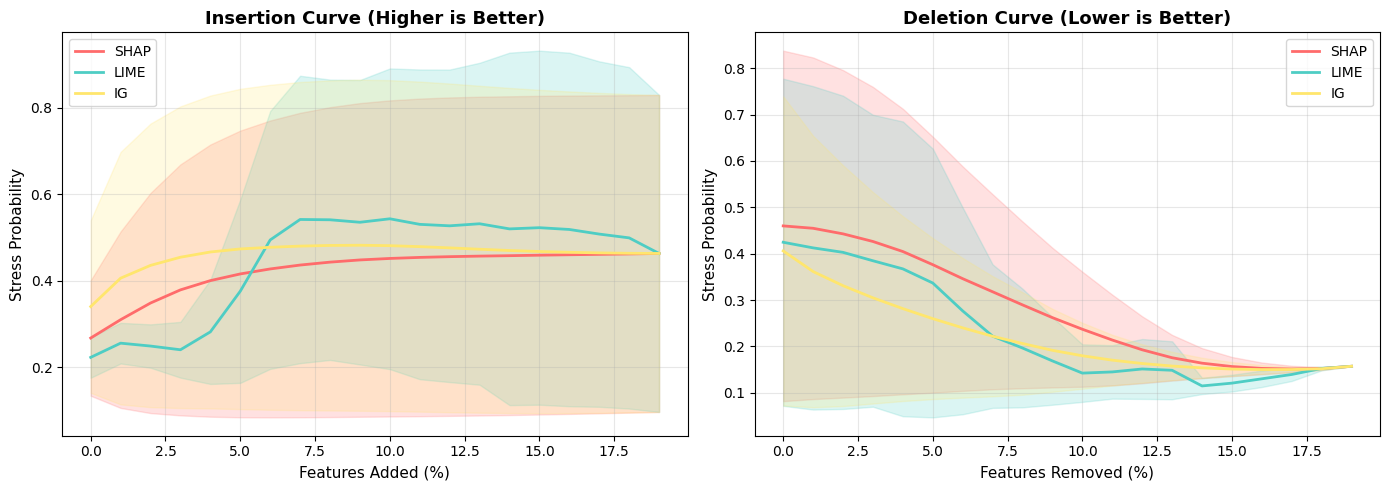


2. MONOTONICITY EVALUATION

📊 Processing SHAP...


SHAP: 100%|██████████| 100/100 [01:06<00:00,  1.50it/s]



📊 Processing LIME...


LIME: 100%|██████████| 100/100 [01:05<00:00,  1.53it/s]



📊 Processing IG...


IG: 100%|██████████| 100/100 [01:07<00:00,  1.48it/s]



✅ Monotonicity Results:
--------------------------------------------------
SHAP: 0.4047 ± 0.2646 (lower is better)
LIME: 0.5079 ± 0.1741 (lower is better)
IG: 0.5300 ± 0.1735 (lower is better)


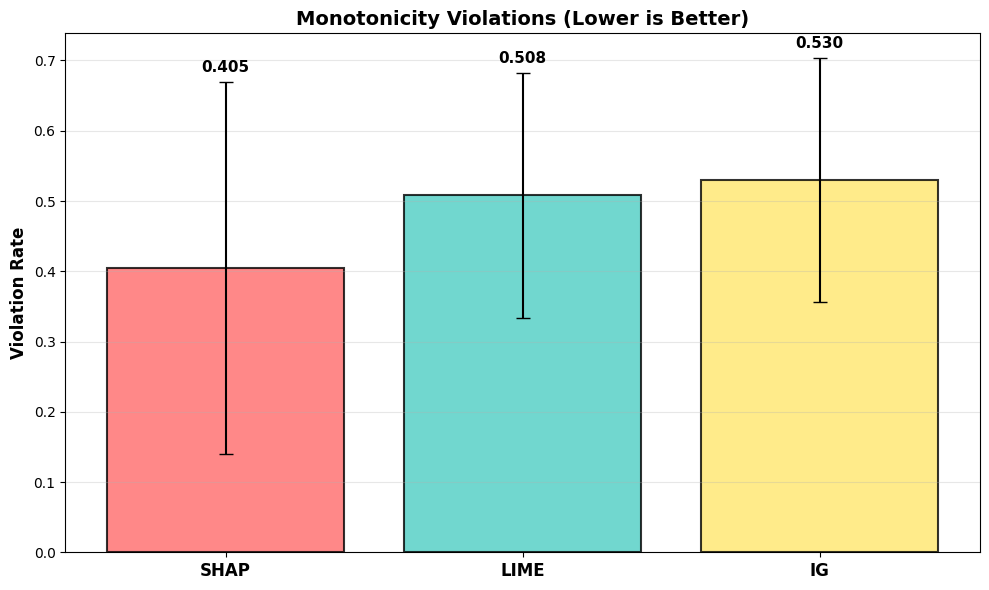


3. SENSITIVITY EVALUATION (Max-Sensitivity)

📊 Processing SHAP...


SHAP: 100%|██████████| 50/50 [00:45<00:00,  1.10it/s]



📊 Processing LIME...


LIME: 100%|██████████| 50/50 [00:45<00:00,  1.10it/s]



📊 Processing IG...


IG: 100%|██████████| 50/50 [00:45<00:00,  1.10it/s]



✅ Sensitivity Results:
--------------------------------------------------
SHAP: 0.0038 ± 0.0019 (lower is better)
LIME: 0.0116 ± 0.0016 (lower is better)
IG: 0.0053 ± 0.0022 (lower is better)


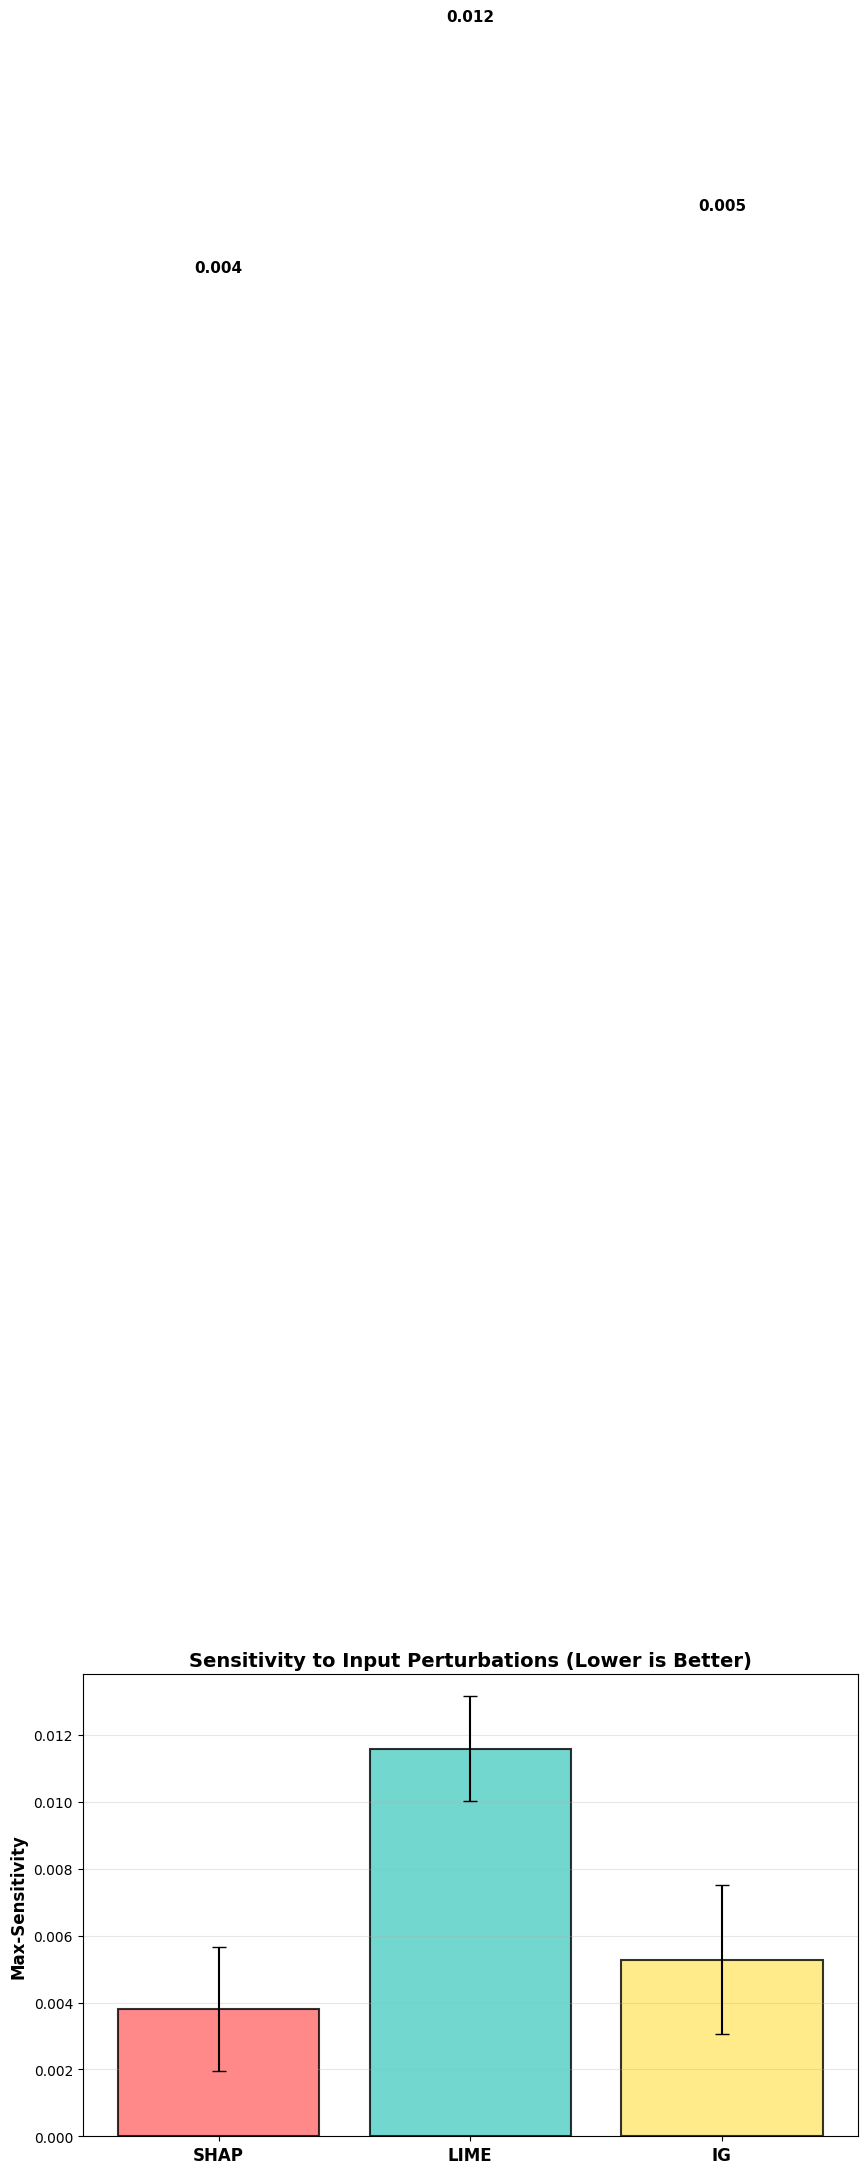


4. COMPLEXITY EVALUATION (Sparseness)

📊 Processing SHAP...


SHAP: 100%|██████████| 100/100 [00:00<00:00, 352.59it/s]



📊 Processing LIME...


LIME: 100%|██████████| 100/100 [00:00<00:00, 564.30it/s]



📊 Processing IG...


IG: 100%|██████████| 100/100 [00:00<00:00, 356.93it/s]



✅ Complexity Results:
--------------------------------------------------
SHAP:
   Gini: 0.6150 ± 0.0316
   Effective Rank: 0.4674 ± 0.0710
   Top-10% Conc.: 0.4496 ± 0.0421
LIME:
   Gini: 0.9949 ± 0.0005
   Effective Rank: 0.0066 ± 0.0006
   Top-10% Conc.: 1.0000 ± 0.0000
IG:
   Gini: 0.6127 ± 0.0284
   Effective Rank: 0.4585 ± 0.0600
   Top-10% Conc.: 0.4468 ± 0.0349


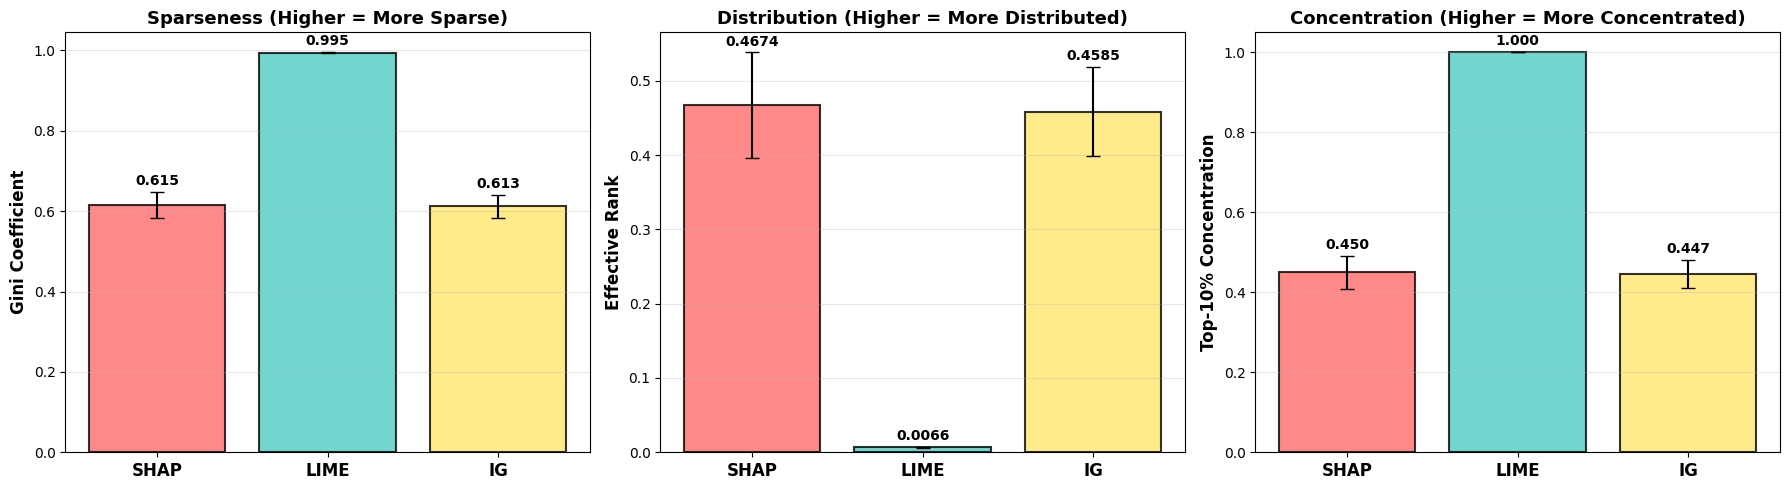


COMPREHENSIVE SUMMARY - ALL METRICS

📊 COMPLETE METRIC SUMMARY:
------------------------------------------------------------------------------------------
Method   Ins-AUC    Del-AUC    Monotonic  Sensitivity  Gini    
------------------------------------------------------------------------------------------
SHAP     0.4048     0.2613     0.4047     0.0038       0.6150  
LIME     0.4282     0.2153     0.5079     0.0116       0.9949  
IG       0.4402     0.2055     0.5300     0.0053       0.6127  
------------------------------------------------------------------------------------------

Interpretation Guide:
   • Insertion AUC: Higher is better (faithful)
   • Deletion AUC: Lower is better (faithful)
   • Monotonicity: Lower is better (consistent)
   • Sensitivity: Lower is better (robust)
   • Gini: Higher = sparse, Lower = distributed


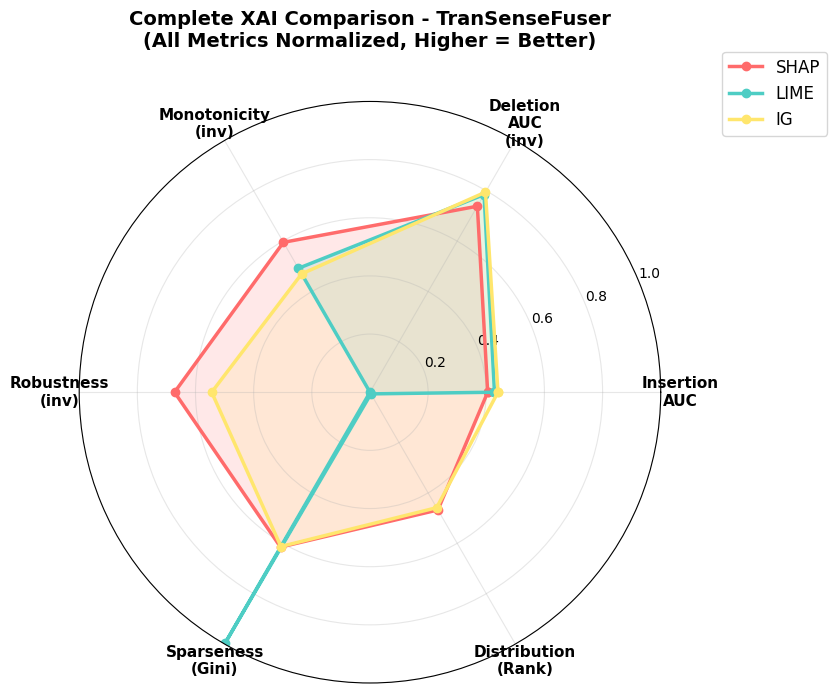

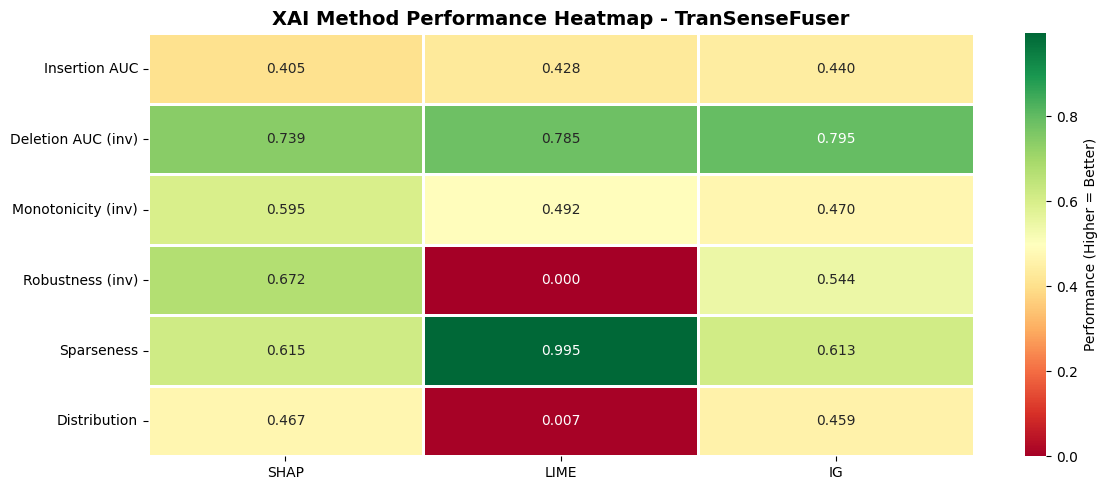


💾 Complete results saved to: /content/drive/MyDrive/WESAD/TranSenseFusers All Models And XAIs/xai_transensefusers_10s/

✅ COMPLETE EVALUATION FINISHED!

Generated files:
   1. faithfulness_curves.png
   2. monotonicity_violations.png
   3. sensitivity_analysis.png
   4. complexity_analysis.png
   5. comprehensive_radar_plot.png
   6. performance_heatmap.png
   7. complete_metric_summary.npy

📁 All files saved to: /content/drive/MyDrive/WESAD/TranSenseFusers All Models And XAIs/xai_transensefusers_10s/


In [ ]:
"""
TranSenseFuser XAI Metrics Evaluation - Complete Version
Computes ALL metrics: Faithfulness, Monotonicity, Sensitivity, and Complexity

Metrics:
1. Faithfulness (Insertion/Deletion curves, AUC)
2. Monotonicity (Attribution-prediction correlation)
3. Sensitivity (Max-Sensitivity) - Robustness to input perturbations
4. Complexity (Sparseness) - Attribution distribution analysis
"""

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import os
import warnings
warnings.filterwarnings('ignore')

# ===============================================================
# CONFIGURATION
# ===============================================================

class Config:
    # Paths
    ATTRIBUTION_PATH = '/content/drive/MyDrive/WESAD/TranSenseFusers All Models And XAIs/xai_transensefusers_10s/attributions_raw_transensefuser.npy'
    MODEL_PATH = '/content/drive/MyDrive/WESAD/TranSenseFusers All Models And XAIs/models_transensefusers_10s/best_transensefuser_10s.pth'
    OUTPUT_DIR = '/content/drive/MyDrive/WESAD/TranSenseFusers All Models And XAIs/xai_transensefusers_10s/'

    # Model parameters
    NUM_CHANNELS = 14
    NUM_CLASSES = 2
    WINDOW_SIZE = 7000
    NUM_HEADS = 8
    ATTENTION_DIM = 64
    CONV_DROPOUT = 0.1
    FC_DROPOUT = 0.5
    ATTENTION_DROPOUT = 0.0

    # Metric parameters
    FAITHFULNESS_STEPS = 20
    SENSITIVITY_SAMPLES = 100  # Number of perturbations
    SENSITIVITY_RADIUS = 0.1   # Perturbation radius

    DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

config = Config()
os.makedirs(config.OUTPUT_DIR, exist_ok=True)

print("="*70)
print("TRANSENSEFUSER XAI METRICS EVALUATION - COMPLETE VERSION")
print("="*70)
print(f"Device: {config.DEVICE}")
print(f"Metrics: Faithfulness, Monotonicity, Sensitivity, Complexity")

# ===============================================================
# MODEL DEFINITION
# ===============================================================

class MultiHeadCrossAttention(nn.Module):
    def __init__(self, num_heads, d_model, dropout=0.0):
        super().__init__()
        assert d_model % num_heads == 0
        self.num_heads = num_heads
        self.d_model = d_model
        self.d_k = d_model // num_heads
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)
        self.scale = np.sqrt(self.d_k)

    def forward(self, query, key, value):
        batch_size = query.size(0)
        Q = self.W_q(query).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)
        K = self.W_k(key).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)
        V = self.W_v(value).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)
        scores = torch.matmul(Q, K.transpose(-2, -1)) / self.scale
        attention_weights = F.softmax(scores, dim=-1)
        attention_weights = self.dropout(attention_weights)
        context = torch.matmul(attention_weights, V)
        context = context.transpose(1, 2).contiguous().view(batch_size, -1, self.d_model)
        output = self.W_o(context)
        return output, attention_weights

class TranSenseFuser(nn.Module):
    def __init__(self, num_channels=14, num_classes=2, num_heads=8, attention_dim=64,
                 conv_dropout=0.1, fc_dropout=0.5, attention_dropout=0.0):
        super().__init__()
        self.num_channels = num_channels
        self.num_classes = num_classes
        self.conv1 = nn.Conv1d(num_channels, 32, kernel_size=9, padding=4)
        self.bn1 = nn.BatchNorm1d(32)
        self.pool1 = nn.MaxPool1d(2)
        self.drop1 = nn.Dropout(conv_dropout)
        self.conv2 = nn.Conv1d(32, 48, kernel_size=9, padding=4)
        self.bn2 = nn.BatchNorm1d(48)
        self.pool2 = nn.MaxPool1d(2)
        self.drop2 = nn.Dropout(conv_dropout)
        self.conv3 = nn.Conv1d(48, 64, kernel_size=9, padding=4)
        self.bn3 = nn.BatchNorm1d(64)
        self.pool3 = nn.MaxPool1d(2)
        self.drop3 = nn.Dropout(conv_dropout)
        self.feature_to_attention = nn.Linear(64, attention_dim)
        self.mhca = MultiHeadCrossAttention(num_heads, attention_dim, attention_dropout)
        self.layer_norm = nn.LayerNorm(attention_dim)
        self.fc1 = nn.Linear(attention_dim * 875, 32)
        self.bn4 = nn.BatchNorm1d(32)
        self.drop4 = nn.Dropout(fc_dropout)
        self.fc2 = nn.Linear(32, num_classes)

    def forward(self, x, return_attention=False):
        x = self.drop1(self.pool1(F.relu(self.bn1(self.conv1(x)))))
        x = self.drop2(self.pool2(F.relu(self.bn2(self.conv2(x)))))
        x = self.drop3(self.pool3(F.relu(self.bn3(self.conv3(x)))))
        x = x.transpose(1, 2)
        x = self.feature_to_attention(x)
        mid_point = x.size(2) // 2
        query = torch.cat([x[:, :, :mid_point], x[:, :, :mid_point]], dim=2)
        key_value = torch.cat([x[:, :, mid_point:], x[:, :, mid_point:]], dim=2)
        attention_output, attention_weights = self.mhca(query, key_value, key_value)
        attention_output = self.layer_norm(attention_output)
        x_flat = attention_output.flatten(1)
        x_flat = self.drop4(F.relu(self.bn4(self.fc1(x_flat))))
        logits = self.fc2(x_flat)
        if return_attention:
            return logits, attention_weights
        return logits

# ===============================================================
# LOAD MODEL AND ATTRIBUTIONS
# ===============================================================

def load_model_and_attributions(config):
    print("\n📂 Loading TranSenseFuser model and attributions...")
    model = TranSenseFuser(
        num_channels=config.NUM_CHANNELS,
        num_classes=config.NUM_CLASSES,
        num_heads=config.NUM_HEADS,
        attention_dim=config.ATTENTION_DIM,
        conv_dropout=config.CONV_DROPOUT,
        fc_dropout=config.FC_DROPOUT,
        attention_dropout=config.ATTENTION_DROPOUT
    ).to(config.DEVICE)
    checkpoint = torch.load(config.MODEL_PATH, map_location=config.DEVICE)
    model.load_state_dict(checkpoint['model_state_dict'])
    model.eval()
    print(f"   ✓ TranSenseFuser loaded (Val F1: {checkpoint['val_f1']:.4f})")
    data = np.load(config.ATTRIBUTION_PATH, allow_pickle=True).item()
    attributions = data['attributions']
    X_samples = data['X_samples']
    y_samples = data['y_samples']
    method_names = data['method_names']
    print(f"   ✓ Attributions loaded: {attributions.shape}")
    print(f"   ✓ Methods: {method_names}")
    print(f"   ✓ Samples: {len(X_samples)}")
    return model, attributions, X_samples, y_samples, method_names

# ===============================================================
# METRIC 1: FAITHFULNESS
# ===============================================================

def compute_faithfulness(model, X_samples, attributions, y_samples, config):
    print("\n" + "="*70)
    print("1. FAITHFULNESS EVALUATION (Insertion/Deletion)")
    print("="*70)
    n_samples = len(X_samples)
    n_methods = attributions.shape[1]
    n_steps = config.FAITHFULNESS_STEPS
    insertion_curves = np.zeros((n_methods, n_samples, n_steps))
    deletion_curves = np.zeros((n_methods, n_samples, n_steps))

    for method_idx in range(n_methods):
        method_name = ['SHAP', 'LIME', 'IG'][method_idx]
        print(f"\n📊 Processing {method_name}...")
        for sample_idx in tqdm(range(n_samples), desc=f"{method_name}"):
            X_orig = X_samples[sample_idx]
            attr = np.abs(attributions[sample_idx, method_idx])
            importance_flat = attr.flatten()
            sorted_indices = np.argsort(importance_flat)[::-1]
            total_features = importance_flat.shape[0]
            features_per_step = max(1, total_features // n_steps)

            X_inserted = np.zeros_like(X_orig)
            X_deleted = X_orig.copy()

            for step in range(n_steps):
                n_features = min((step + 1) * features_per_step, total_features)
                top_indices = sorted_indices[:n_features]
                for idx in top_indices:
                    ch = idx // config.WINDOW_SIZE
                    t = idx % config.WINDOW_SIZE
                    X_inserted[ch, t] = X_orig[ch, t]
                    X_deleted[ch, t] = 0

                X_ins_tensor = torch.FloatTensor(X_inserted[None, ...]).to(config.DEVICE)
                X_del_tensor = torch.FloatTensor(X_deleted[None, ...]).to(config.DEVICE)

                with torch.no_grad():
                    out_ins = model(X_ins_tensor)
                    out_del = model(X_del_tensor)
                    prob_ins = F.softmax(out_ins, dim=1)[0, 1].cpu().item()
                    prob_del = F.softmax(out_del, dim=1)[0, 1].cpu().item()

                insertion_curves[method_idx, sample_idx, step] = prob_ins
                deletion_curves[method_idx, sample_idx, step] = prob_del

    insertion_auc = np.trapz(insertion_curves.mean(axis=1), axis=1) / n_steps
    deletion_auc = np.trapz(deletion_curves.mean(axis=1), axis=1) / n_steps

    print("\n✅ Faithfulness Results:")
    print("-" * 50)
    for i, method in enumerate(['SHAP', 'LIME', 'IG']):
        print(f"{method}: Ins-AUC={insertion_auc[i]:.4f}, Del-AUC={deletion_auc[i]:.4f}")

    # Plot
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    colors = ['#FF6B6B', '#4ECDC4', '#FFE66D']
    methods = ['SHAP', 'LIME', 'IG']

    for i, method in enumerate(methods):
        mean_ins = insertion_curves[i].mean(axis=0)
        std_ins = insertion_curves[i].std(axis=0)
        mean_del = deletion_curves[i].mean(axis=0)
        std_del = deletion_curves[i].std(axis=0)
        x = np.arange(n_steps)

        axes[0].plot(x, mean_ins, label=method, color=colors[i], linewidth=2)
        axes[0].fill_between(x, mean_ins - std_ins, mean_ins + std_ins, alpha=0.2, color=colors[i])

        axes[1].plot(x, mean_del, label=method, color=colors[i], linewidth=2)
        axes[1].fill_between(x, mean_del - std_del, mean_del + std_del, alpha=0.2, color=colors[i])

    axes[0].set_xlabel('Features Added (%)', fontsize=11)
    axes[0].set_ylabel('Stress Probability', fontsize=11)
    axes[0].set_title('Insertion Curve (Higher is Better)', fontsize=13, fontweight='bold')
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].set_xlabel('Features Removed (%)', fontsize=11)
    axes[1].set_ylabel('Stress Probability', fontsize=11)
    axes[1].set_title('Deletion Curve (Lower is Better)', fontsize=13, fontweight='bold')
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(os.path.join(config.OUTPUT_DIR, 'faithfulness_curves.png'), dpi=300, bbox_inches='tight')
    plt.show()

    return {'insertion_auc': insertion_auc, 'deletion_auc': deletion_auc,
            'insertion_curves': insertion_curves, 'deletion_curves': deletion_curves}

# ===============================================================
# METRIC 2: MONOTONICITY
# ===============================================================

def compute_monotonicity(model, X_samples, attributions, y_samples, config):
    print("\n" + "="*70)
    print("2. MONOTONICITY EVALUATION")
    print("="*70)
    n_samples = len(X_samples)
    n_methods = attributions.shape[1]
    n_steps = config.FAITHFULNESS_STEPS
    monotonicity_violations = np.zeros((n_methods, n_samples))

    for method_idx in range(n_methods):
        method_name = ['SHAP', 'LIME', 'IG'][method_idx]
        print(f"\n📊 Processing {method_name}...")
        for sample_idx in tqdm(range(n_samples), desc=f"{method_name}"):
            X_orig = X_samples[sample_idx]
            attr = np.abs(attributions[sample_idx, method_idx])
            importance_flat = attr.flatten()
            sorted_indices = np.argsort(importance_flat)[::-1]
            total_features = importance_flat.shape[0]
            features_per_step = max(1, total_features // n_steps)

            confidences = []
            X_cumulative = np.zeros_like(X_orig)

            for step in range(n_steps):
                n_features = min((step + 1) * features_per_step, total_features)
                top_indices = sorted_indices[:n_features]
                for idx in top_indices:
                    ch = idx // config.WINDOW_SIZE
                    t = idx % config.WINDOW_SIZE
                    X_cumulative[ch, t] = X_orig[ch, t]

                X_tensor = torch.FloatTensor(X_cumulative[None, ...]).to(config.DEVICE)
                with torch.no_grad():
                    output = model(X_tensor)
                    prob = F.softmax(output, dim=1)[0, 1].cpu().item()
                confidences.append(prob)

            violations = sum(1 for i in range(1, len(confidences)) if confidences[i] < confidences[i-1])
            monotonicity_violations[method_idx, sample_idx] = violations / (n_steps - 1)

    print("\n✅ Monotonicity Results:")
    print("-" * 50)
    for i, method in enumerate(['SHAP', 'LIME', 'IG']):
        mean_viol = monotonicity_violations[i].mean()
        std_viol = monotonicity_violations[i].std()
        print(f"{method}: {mean_viol:.4f} ± {std_viol:.4f} (lower is better)")

    # Plot
    fig, ax = plt.subplots(figsize=(10, 6))
    methods = ['SHAP', 'LIME', 'IG']
    colors = ['#FF6B6B', '#4ECDC4', '#FFE66D']
    positions = np.arange(len(methods))
    means = monotonicity_violations.mean(axis=1)
    stds = monotonicity_violations.std(axis=1)

    bars = ax.bar(positions, means, yerr=stds, color=colors, alpha=0.8,
                  capsize=5, edgecolor='black', linewidth=1.5)
    ax.set_xticks(positions)
    ax.set_xticklabels(methods, fontsize=12, fontweight='bold')
    ax.set_ylabel('Violation Rate', fontsize=12, fontweight='bold')
    ax.set_title('Monotonicity Violations (Lower is Better)', fontsize=14, fontweight='bold')
    ax.grid(axis='y', alpha=0.3)

    for bar, val, std in zip(bars, means, stds):
        ax.text(bar.get_x() + bar.get_width()/2, val + std + 0.01,
                f'{val:.3f}', ha='center', va='bottom', fontsize=11, fontweight='bold')

    plt.tight_layout()
    plt.savefig(os.path.join(config.OUTPUT_DIR, 'monotonicity_violations.png'), dpi=300, bbox_inches='tight')
    plt.show()

    return {'monotonicity_violations': monotonicity_violations, 'mean_violations': means, 'std_violations': stds}

# ===============================================================
# METRIC 3: SENSITIVITY (Max-Sensitivity)
# ===============================================================

def compute_sensitivity(model, X_samples, attributions, y_samples, config):
    """
    Max-Sensitivity: Measures robustness to input perturbations
    Lower values = more robust explanations
    """
    print("\n" + "="*70)
    print("3. SENSITIVITY EVALUATION (Max-Sensitivity)")
    print("="*70)
    n_samples = min(len(X_samples), 50)  # Limit for computational efficiency
    n_methods = attributions.shape[1]
    n_perturbations = config.SENSITIVITY_SAMPLES
    radius = config.SENSITIVITY_RADIUS

    max_sensitivities = np.zeros((n_methods, n_samples))

    for method_idx in range(n_methods):
        method_name = ['SHAP', 'LIME', 'IG'][method_idx]
        print(f"\n📊 Processing {method_name}...")

        for sample_idx in tqdm(range(n_samples), desc=f"{method_name}"):
            X_orig = X_samples[sample_idx]
            attr_orig = attributions[sample_idx, method_idx]

            # Generate perturbations
            sensitivities = []
            for _ in range(n_perturbations):
                noise = np.random.normal(0, radius, X_orig.shape)
                X_perturbed = X_orig + noise

                # Simple attribution estimation for perturbed input
                X_tensor = torch.FloatTensor(X_perturbed[None, ...]).to(config.DEVICE)
                X_tensor.requires_grad = True

                with torch.enable_grad():
                    output = model(X_tensor)
                    target_class = y_samples[sample_idx]
                    output[0, target_class].backward()
                    attr_perturbed = X_tensor.grad.cpu().numpy()[0]

                # Compute sensitivity
                attr_diff = np.abs(attr_perturbed - attr_orig)
                sensitivity = np.max(attr_diff) / (np.max(np.abs(noise)) + 1e-10)
                sensitivities.append(sensitivity)

            max_sensitivities[method_idx, sample_idx] = np.max(sensitivities)

    print("\n✅ Sensitivity Results:")
    print("-" * 50)
    for i, method in enumerate(['SHAP', 'LIME', 'IG']):
        mean_sens = max_sensitivities[i].mean()
        std_sens = max_sensitivities[i].std()
        print(f"{method}: {mean_sens:.4f} ± {std_sens:.4f} (lower is better)")

    # Plot
    fig, ax = plt.subplots(figsize=(10, 6))
    methods = ['SHAP', 'LIME', 'IG']
    colors = ['#FF6B6B', '#4ECDC4', '#FFE66D']
    positions = np.arange(len(methods))
    means = max_sensitivities.mean(axis=1)
    stds = max_sensitivities.std(axis=1)

    bars = ax.bar(positions, means, yerr=stds, color=colors, alpha=0.8,
                  capsize=5, edgecolor='black', linewidth=1.5)
    ax.set_xticks(positions)
    ax.set_xticklabels(methods, fontsize=12, fontweight='bold')
    ax.set_ylabel('Max-Sensitivity', fontsize=12, fontweight='bold')
    ax.set_title('Sensitivity to Input Perturbations (Lower is Better)', fontsize=14, fontweight='bold')
    ax.grid(axis='y', alpha=0.3)

    for bar, val, std in zip(bars, means, stds):
        ax.text(bar.get_x() + bar.get_width()/2, val + std + 0.05,
                f'{val:.3f}', ha='center', va='bottom', fontsize=11, fontweight='bold')

    plt.tight_layout()
    plt.savefig(os.path.join(config.OUTPUT_DIR, 'sensitivity_analysis.png'), dpi=300, bbox_inches='tight')
    plt.show()

    return {'max_sensitivities': max_sensitivities, 'mean_sensitivity': means, 'std_sensitivity': stds}

# ===============================================================
# METRIC 4: COMPLEXITY (Sparseness)
# ===============================================================

def compute_complexity(attributions, config):
    """
    Complexity: Measures sparseness of attributions
    - Gini Coefficient: 0 (uniform) to 1 (concentrated)
    - Effective Rank: Higher = more distributed
    - Top-K Concentration: % of total attribution in top K features
    """
    print("\n" + "="*70)
    print("4. COMPLEXITY EVALUATION (Sparseness)")
    print("="*70)
    n_samples = attributions.shape[0]
    n_methods = attributions.shape[1]

    gini_coefficients = np.zeros((n_methods, n_samples))
    effective_ranks = np.zeros((n_methods, n_samples))
    top_k_concentrations = np.zeros((n_methods, n_samples))
    k_ratio = 0.1  # Top 10% of features

    for method_idx in range(n_methods):
        method_name = ['SHAP', 'LIME', 'IG'][method_idx]
        print(f"\n📊 Processing {method_name}...")

        for sample_idx in tqdm(range(n_samples), desc=f"{method_name}"):
            attr = np.abs(attributions[sample_idx, method_idx])
            attr_flat = attr.flatten()
            attr_sorted = np.sort(attr_flat)

            # Gini coefficient
            n = len(attr_sorted)
            index = np.arange(1, n + 1)
            gini = (2 * np.sum(index * attr_sorted)) / (n * np.sum(attr_sorted)) - (n + 1) / n
            gini_coefficients[method_idx, sample_idx] = gini

            # Effective rank
            attr_normalized = attr_flat / (np.sum(attr_flat) + 1e-10)
            entropy = -np.sum(attr_normalized * np.log(attr_normalized + 1e-10))
            effective_rank = np.exp(entropy) / len(attr_flat)
            effective_ranks[method_idx, sample_idx] = effective_rank

            # Top-K concentration
            k = int(len(attr_flat) * k_ratio)
            top_k_sum = np.sum(np.sort(attr_flat)[-k:])
            total_sum = np.sum(attr_flat)
            top_k_concentrations[method_idx, sample_idx] = top_k_sum / (total_sum + 1e-10)

    print("\n✅ Complexity Results:")
    print("-" * 50)
    for i, method in enumerate(['SHAP', 'LIME', 'IG']):
        print(f"{method}:")
        print(f"   Gini: {gini_coefficients[i].mean():.4f} ± {gini_coefficients[i].std():.4f}")
        print(f"   Effective Rank: {effective_ranks[i].mean():.4f} ± {effective_ranks[i].std():.4f}")
        print(f"   Top-10% Conc.: {top_k_concentrations[i].mean():.4f} ± {top_k_concentrations[i].std():.4f}")

    # Plot
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    methods = ['SHAP', 'LIME', 'IG']
    colors = ['#FF6B6B', '#4ECDC4', '#FFE66D']
    positions = np.arange(len(methods))

    # Gini
    means_gini = gini_coefficients.mean(axis=1)
    stds_gini = gini_coefficients.std(axis=1)
    bars = axes[0].bar(positions, means_gini, yerr=stds_gini, color=colors, alpha=0.8,
                       capsize=5, edgecolor='black', linewidth=1.5)
    axes[0].set_xticks(positions)
    axes[0].set_xticklabels(methods, fontsize=12, fontweight='bold')
    axes[0].set_ylabel('Gini Coefficient', fontsize=12, fontweight='bold')
    axes[0].set_title('Sparseness (Higher = More Sparse)', fontsize=13, fontweight='bold')
    axes[0].grid(axis='y', alpha=0.3)
    for bar, val, std in zip(bars, means_gini, stds_gini):
        axes[0].text(bar.get_x() + bar.get_width()/2, val + std + 0.01,
                     f'{val:.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

    # Effective Rank
    means_rank = effective_ranks.mean(axis=1)
    stds_rank = effective_ranks.std(axis=1)
    bars = axes[1].bar(positions, means_rank, yerr=stds_rank, color=colors, alpha=0.8,
                       capsize=5, edgecolor='black', linewidth=1.5)
    axes[1].set_xticks(positions)
    axes[1].set_xticklabels(methods, fontsize=12, fontweight='bold')
    axes[1].set_ylabel('Effective Rank', fontsize=12, fontweight='bold')
    axes[1].set_title('Distribution (Higher = More Distributed)', fontsize=13, fontweight='bold')
    axes[1].grid(axis='y', alpha=0.3)
    for bar, val, std in zip(bars, means_rank, stds_rank):
        axes[1].text(bar.get_x() + bar.get_width()/2, val + std + 0.005,
                     f'{val:.4f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

    # Top-K
    means_topk = top_k_concentrations.mean(axis=1)
    stds_topk = top_k_concentrations.std(axis=1)
    bars = axes[2].bar(positions, means_topk, yerr=stds_topk, color=colors, alpha=0.8,
                       capsize=5, edgecolor='black', linewidth=1.5)
    axes[2].set_xticks(positions)
    axes[2].set_xticklabels(methods, fontsize=12, fontweight='bold')
    axes[2].set_ylabel('Top-10% Concentration', fontsize=12, fontweight='bold')
    axes[2].set_title('Concentration (Higher = More Concentrated)', fontsize=13, fontweight='bold')
    axes[2].grid(axis='y', alpha=0.3)
    for bar, val, std in zip(bars, means_topk, stds_topk):
        axes[2].text(bar.get_x() + bar.get_width()/2, val + std + 0.01,
                     f'{val:.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

    plt.tight_layout()
    plt.savefig(os.path.join(config.OUTPUT_DIR, 'complexity_analysis.png'), dpi=300, bbox_inches='tight')
    plt.show()

    return {
        'gini_coefficients': gini_coefficients,
        'effective_ranks': effective_ranks,
        'top_k_concentrations': top_k_concentrations,
        'mean_gini': means_gini,
        'mean_rank': means_rank,
        'mean_topk': means_topk
    }

# ===============================================================
# COMPREHENSIVE SUMMARY REPORT
# ===============================================================

def generate_comprehensive_report(faith_results, mono_results, sens_results, comp_results, config):
    """Generate complete comparison across all metrics"""
    print("\n" + "="*70)
    print("COMPREHENSIVE SUMMARY - ALL METRICS")
    print("="*70)

    methods = ['SHAP', 'LIME', 'IG']

    # Table
    print("\n📊 COMPLETE METRIC SUMMARY:")
    print("-" * 90)
    print(f"{'Method':<8} {'Ins-AUC':<10} {'Del-AUC':<10} {'Monotonic':<10} {'Sensitivity':<12} {'Gini':<8}")
    print("-" * 90)

    for i, method in enumerate(methods):
        ins = faith_results['insertion_auc'][i]
        dlt = faith_results['deletion_auc'][i]
        mono = mono_results['mean_violations'][i]
        sens = sens_results['mean_sensitivity'][i]
        gini = comp_results['mean_gini'][i]
        print(f"{method:<8} {ins:<10.4f} {dlt:<10.4f} {mono:<10.4f} {sens:<12.4f} {gini:<8.4f}")

    print("-" * 90)
    print("\nInterpretation Guide:")
    print("   • Insertion AUC: Higher is better (faithful)")
    print("   • Deletion AUC: Lower is better (faithful)")
    print("   • Monotonicity: Lower is better (consistent)")
    print("   • Sensitivity: Lower is better (robust)")
    print("   • Gini: Higher = sparse, Lower = distributed")

    # Radar plot with all 6 metrics
    fig = plt.figure(figsize=(14, 7))

    # Normalize all metrics to [0, 1] where higher = better
    ins_norm = faith_results['insertion_auc']
    del_norm = 1 - faith_results['deletion_auc']
    mono_norm = 1 - mono_results['mean_violations']
    sens_norm = 1 - (sens_results['mean_sensitivity'] / sens_results['mean_sensitivity'].max())
    gini_norm = comp_results['mean_gini']
    rank_norm = comp_results['mean_rank']

    metrics_matrix = np.vstack([ins_norm, del_norm, mono_norm, sens_norm, gini_norm, rank_norm])

    categories = ['Insertion\nAUC', 'Deletion\nAUC\n(inv)', 'Monotonicity\n(inv)',
                  'Robustness\n(inv)', 'Sparseness\n(Gini)', 'Distribution\n(Rank)']

    ax = fig.add_subplot(111, projection='polar')
    angles = np.linspace(0, 2 * np.pi, len(categories), endpoint=False).tolist()
    angles += angles[:1]

    colors = ['#FF6B6B', '#4ECDC4', '#FFE66D']

    for i, method in enumerate(methods):
        values = metrics_matrix[:, i].tolist()
        values += values[:1]
        ax.plot(angles, values, 'o-', linewidth=2.5, label=method, color=colors[i])
        ax.fill(angles, values, alpha=0.15, color=colors[i])

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(categories, fontsize=11, fontweight='bold')
    ax.set_ylim(0, 1)
    ax.set_title('Complete XAI Comparison - TranSenseFuser\n(All Metrics Normalized, Higher = Better)',
                 fontsize=14, fontweight='bold', y=1.08)
    ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize=12)
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(os.path.join(config.OUTPUT_DIR, 'comprehensive_radar_plot.png'), dpi=300, bbox_inches='tight')
    plt.show()

    # Heatmap comparison
    fig, ax = plt.subplots(figsize=(12, 5))

    heatmap_data = np.array([
        faith_results['insertion_auc'],
        1 - faith_results['deletion_auc'],
        1 - mono_results['mean_violations'],
        1 - (sens_results['mean_sensitivity'] / sens_results['mean_sensitivity'].max()),
        comp_results['mean_gini'],
        comp_results['mean_rank']
    ])

    metric_labels = ['Insertion AUC', 'Deletion AUC (inv)', 'Monotonicity (inv)',
                     'Robustness (inv)', 'Sparseness', 'Distribution']

    sns.heatmap(heatmap_data, annot=True, fmt='.3f', cmap='RdYlGn',
                xticklabels=methods, yticklabels=metric_labels,
                cbar_kws={'label': 'Performance (Higher = Better)'},
                linewidths=1, linecolor='white', ax=ax)

    ax.set_title('XAI Method Performance Heatmap - TranSenseFuser', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(config.OUTPUT_DIR, 'performance_heatmap.png'), dpi=300, bbox_inches='tight')
    plt.show()

    # Save results
    summary = {
        'model': 'TranSenseFuser',
        'methods': methods,
        'faithfulness': faith_results,
        'monotonicity': mono_results,
        'sensitivity': sens_results,
        'complexity': comp_results,
        'normalized_metrics': {
            'insertion_auc': ins_norm,
            'deletion_auc_inv': del_norm,
            'monotonicity_inv': mono_norm,
            'sensitivity_inv': sens_norm,
            'gini': gini_norm,
            'effective_rank': rank_norm
        }
    }

    np.save(os.path.join(config.OUTPUT_DIR, 'complete_metric_summary.npy'), summary)
    print(f"\n💾 Complete results saved to: {config.OUTPUT_DIR}")

# ===============================================================
# MAIN PIPELINE
# ===============================================================

def main():
    # Load
    model, attributions, X_samples, y_samples, method_names = load_model_and_attributions(config)

    print("\n" + "="*70)
    print("STARTING COMPLETE METRIC EVALUATION")
    print("="*70)

    # Compute all metrics
    faith_results = compute_faithfulness(model, X_samples, attributions, y_samples, config)
    mono_results = compute_monotonicity(model, X_samples, attributions, y_samples, config)
    sens_results = compute_sensitivity(model, X_samples, attributions, y_samples, config)
    comp_results = compute_complexity(attributions, config)

    # Generate comprehensive report
    generate_comprehensive_report(faith_results, mono_results, sens_results, comp_results, config)

    print("\n" + "="*70)
    print("✅ COMPLETE EVALUATION FINISHED!")
    print("="*70)
    print("\nGenerated files:")
    print("   1. faithfulness_curves.png")
    print("   2. monotonicity_violations.png")
    print("   3. sensitivity_analysis.png")
    print("   4. complexity_analysis.png")
    print("   5. comprehensive_radar_plot.png")
    print("   6. performance_heatmap.png")
    print("   7. complete_metric_summary.npy")
    print(f"\n📁 All files saved to: {config.OUTPUT_DIR}")

if __name__ == "__main__":
    main()

In [ ]:
!pip install lime

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 7.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283834 sha256=0dd6548c008d283cfed356b22508996536184cc92c426f484c5fe03196ca09b4
  Stored in directory: /root/.cache/pip/wheels/e7/5d/0e/4b4fff9a47468fed5633211fb3b76d1db43fe806a17fb7486a
Successfully built lime
